In [1]:
import torch

print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

!nvidia-smi

CUDA: True
GPU: Tesla T4
Wed Nov 18 01:35:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------

In [2]:
!pip install -q transformers accelerate bitsandbytes sentencepiece scikit-learn

In [3]:
import torch
import pandas as pd
import transformers
import sklearn

print("Pandas:", pd.__version__)
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Pandas: 2.2.3
Transformers: 5.22.1
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [4]:
import os
import json
import pandas as pd
import glob

files = (
    glob.glob("/content/dataset_10k.jsonl")
)

print("Uploaded files:")
for f in files:
    print(f)

Uploaded files:
/content/dataset_10k.jsonl


In [5]:
DATA_PATH = "/content/dataset_10k.jsonl"

In [6]:
with open(DATA_PATH, "r", encoding="utf-8") as f:
    content = f.read().strip()

try:
    data = json.loads(content)

    if isinstance(data, dict):
        data = [data]

except json.JSONDecodeError:
    data = [
        json.loads(line)
        for line in content.splitlines()
        if line.strip()
    ]

df = pd.DataFrame(data)

print("Total records:", len(df))
print("Columns:", df.columns.tolist())

print("\nLanguage distribution:")
print(df["language"].value_counts())

print("\nCategory distribution:")
print(df["category"].value_counts())

display(df.head())

Total records: 10265
Columns: ['question_id', 'language', 'category', 'question', 'expected', 'domain', 'unique_id']

Language distribution:
language
Marathi     2112
Gujarati    2107
Odia        2087
Hindi       2067
English     1892
Name: count, dtype: int64

Category distribution:
category
factual_questions                   1950
semantically_incorrect_questions    1825
indian_questions                    1135
word_ordering_questions             1005
true_false_questions                 985
chrono_questions                     980
maths_questions                      875
ner_questions                        805
reasoning_questions                  705
Name: count, dtype: int64


,question_id,language,category,question,expected,domain,unique_id
0,1,English,chrono_questions,Arrange the following events in chronological ...,"Battle of Poitiers, Mexican-American War, Seco...",NaN,070000000101
1,1,Gujarati,chrono_questions,નીચેની ઘટનાઓને કાલક્રમિક ક્રમમાં ગોઠવો: મેક્સિ...,"પોઇટિયર્સનું યુદ્ધ, મેક્સિકન-અમેરિકન યુદ્ધ, બી...",NaN,070000000103
2,1,Hindi,chrono_questions,निम्नलिखित घटनाओं को कालानुक्रमिक क्रम में व्य...,"पोइटियर्स का युद्ध, मैक्सिकन-अमेरिकी युद्ध, दू...",NaN,070000000102
3,1,Marathi,chrono_questions,खालील घटनांची कालक्रमानुसार मांडणी करा: मेक्सि...,"पॉइटियर्सची लढाई, मेक्सिकन-अमेरिकन युद्ध, दुसर...",NaN,070000000104
4,1,Odia,chrono_questions,ନିମ୍ନଲିଖିତ ଘଟଣାଗୁଡ଼ିକୁ କାଳାନୁକ୍ରମିକ କ୍ରମରେ ସଜା...,"ପୋଇଟିଅର୍ସ ଯୁଦ୍ଧ, ମେକ୍ସିକାନ୍-ଆମେରିକାନ୍ ଯୁଦ୍ଧ, ଦ...",NaN,070000000105


In [7]:
N_PER_GROUP = 2

sample_groups = []

for (language, category), group in df.groupby(
    ["language", "category"]
):
    sample_groups.append(
        group.sample(
            n=min(N_PER_GROUP, len(group)),
            random_state=42
        )
    )

test_df = pd.concat(
    sample_groups,
    ignore_index=True
)

print("Selected questions:", len(test_df))

display(
    test_df.groupby(
        ["language", "category"]
    ).size().reset_index(name="count")
)

Selected questions: 88


,language,category,count
0,English,chrono_questions,2
1,English,factual_questions,2
2,English,indian_questions,2
3,English,maths_questions,2
4,English,reasoning_questions,2
5,English,semantically_incorrect_questions,2
6,English,true_false_questions,2
7,English,word_ordering_questions,2
8,Gujarati,chrono_questions,2
9,Gujarati,factual_questions,2


In [8]:
test_df.to_csv(
    "/content/bhram_test_sample.csv",
    index=False
)

In [9]:
import re

def evaluate_true_false(expected, prediction):

    expected = str(expected).strip().lower()
    prediction = str(prediction).strip().lower()

    if expected not in ["true", "false"]:
        return None

    # Look for an explicit answer
    prediction = re.sub(
        r"^(the answer is|answer:|final answer:)\s*",
        "",
        prediction
    )

    if prediction.startswith("true"):
        return expected == "true"

    if prediction.startswith("false"):
        return expected == "false"

    # If there is no explicit answer, leave for manual evaluation
    return None

In [10]:
import re

def extract_numbers(text):

    text = str(text)

    numbers = re.findall(
        r"-?\d+(?:\.\d+)?",
        text
    )

    if len(numbers) == 0:
        return None

    return float(numbers[-1])


def evaluate_math(expected, prediction):

    expected_num = extract_numbers(expected)
    predicted_num = extract_numbers(prediction)

    if expected_num is None or predicted_num is None:
        return None

    return expected_num == predicted_num

In [11]:
tf_df = df[
    df["category"] == "true_false_questions"
].copy()

tf_df["expected_label"] = (
    tf_df["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

print("Total True/False questions:", len(tf_df))

print("\nExpected distribution:")
print(tf_df["expected_label"].value_counts())

Total True/False questions: 985

Expected distribution:
expected_label
TRUE     495
FALSE    490
Name: count, dtype: int64


In [12]:
N_PER_GROUP = 20

tf_sample = (
    tf_df.groupby(
        ["language", "expected_label"],
        group_keys=False
    )
    .sample(n=N_PER_GROUP, random_state=42)
    .reset_index(drop=True)
)

print("Selected questions:", len(tf_sample))

display(
    tf_sample.groupby(
        ["language", "expected_label"]
    ).size().unstack(fill_value=0)
)

tf_sample.to_csv(
    "/content/TF_Balanced_200_Questions.csv",
    index=False
)

Selected questions: 200


expected_label,FALSE,TRUE
language,,
English,20,20
Gujarati,20,20
Hindi,20,20
Marathi,20,20
Odia,20,20


In [13]:
def generate_tf_answer(model, tokenizer, question):

    messages = [
        {
            "role": "system",
            "content": (
                "You are a strict True/False classification system. "
                "Determine whether the statement is factually true or false. "
                "Respond with exactly one word: either TRUE or FALSE."
            )
        },
        {
            "role": "user",
            "content": f"Statement: {question}\n\nAnswer:"
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        # Increased max_new_tokens to 15 to prevent truncation if the model adds padding
        outputs = model.generate(
            **inputs,
            max_new_tokens=15,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return answer.strip()

In [14]:
MODELS = {
    # SLM
    "Qwen_0.5B": {
        "path": "Qwen/Qwen2.5-0.5B-Instruct",
        "type": "SLM"
    },
    "SmolLM2_1.7B": {
        "path": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
        "type": "SLM"
    },
    "TinyLlama_1.1B": {
        "path": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
        "type": "SLM"
    },

    # LLM
    "Qwen_7B": {
        "path": "Qwen/Qwen2.5-7B-Instruct",
        "type": "LLM"
    },
    "Mistral_7B": {
        "path": "mistralai/Mistral-7B-Instruct-v0.3",
        "type": "LLM"
    },
    "Zephyr_7B": {
        "path": "HuggingFaceH4/zephyr-7b-beta",
        "type": "LLM"
    }
}

In [15]:
import os
import gc
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

tf_results = []

for model_name, model_info in MODELS.items():

    print("\nProcessing:", model_name)

    model_path = model_info["path"]

    if model_info["type"] == "LLM":

        quant_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_compute_dtype=torch.float16,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True
        )

        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            quantization_config=quant_config,
            device_map="auto"
        )

    else:

        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            torch_dtype=torch.float16,
            device_map="auto"
        )

    tokenizer = AutoTokenizer.from_pretrained(model_path)

    model.eval()

    # Use the same 200 questions for every model
    for _, item in tf_sample.iterrows():

        prediction = generate_tf_answer(
            model,
            tokenizer,
            item["question"]
        )

        tf_results.append({
            "model": model_name,
            "model_type": model_info["type"],
            "question_id": item["question_id"],
            "unique_id": item["unique_id"],
            "language": item["language"],
            "category": item["category"],
            "question": item["question"],
            "expected": item["expected"],
            "prediction": prediction
        })

    # Save after each model so completed results are preserved
    os.makedirs("/content/tf_results", exist_ok=True)

    model_df = pd.DataFrame([
        x for x in tf_results
        if x["model"] == model_name
    ])

    model_df.to_csv(
        f"/content/tf_results/{model_name}.csv",
        index=False
    )

    print("Completed:", model_name)

    del model
    del tokenizer

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


tf_results_df = pd.DataFrame(tf_results)

tf_results_df.to_csv(
    "/content/TF_All_Models_Results.csv",
    index=False
)

print("\nAll six models completed!")
print("Total predictions:", len(tf_results_df))

display(tf_results_df.head())


Processing: Qwen_0.5B


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

... (62 outputs left out)

added_tokens.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/168 [00:00<?, ?B/s]

Completed: Zephyr_7B

All six models completed!
Total predictions: 1200


,model,model_type,question_id,unique_id,language,category,question,expected,prediction
0,Qwen_0.5B,SLM,1291,080000129101,English,true_false_questions,The Cosmic Microwave Background was discovered...,False,FALSE
1,Qwen_0.5B,SLM,951,080000095101,English,true_false_questions,The sitar was invented in the 17th century.,False,FALSE
2,Qwen_0.5B,SLM,1931,080000193101,English,true_false_questions,Powerful and general theoretical methods devel...,False,FALSE
3,Qwen_0.5B,SLM,381,080040038101,English,true_false_questions,Solar module prices fell 35 percent to less th...,False,FALSE
4,Qwen_0.5B,SLM,1681,080000168101,English,true_false_questions,She named the chemical element polonium after ...,False,FALSE


In [16]:
def extract_tf(text):

    text = str(text).strip().upper()

    match = re.match(
        r"^(TRUE|FALSE)\b",
        text
    )

    if match:
        return match.group(1)

    return "INVALID"


tf_results_df["predicted_label"] = (
    tf_results_df["prediction"].apply(extract_tf)
)

tf_results_df["correct"] = (
    tf_results_df["expected"].str.upper().str.strip()
    ==
    tf_results_df["predicted_label"]
)

display(tf_results_df)

,model,model_type,question_id,unique_id,language,category,question,expected,prediction,predicted_label,correct
0,Qwen_0.5B,SLM,1291,080000129101,English,true_false_questions,The Cosmic Microwave Background was discovered...,False,FALSE,FALSE,True
1,Qwen_0.5B,SLM,951,080000095101,English,true_false_questions,The sitar was invented in the 17th century.,False,FALSE,FALSE,True
2,Qwen_0.5B,SLM,1931,080000193101,English,true_false_questions,Powerful and general theoretical methods devel...,False,FALSE,FALSE,True
3,Qwen_0.5B,SLM,381,080040038101,English,true_false_questions,Solar module prices fell 35 percent to less th...,False,FALSE,FALSE,True
4,Qwen_0.5B,SLM,1681,080000168101,English,true_false_questions,She named the chemical element polonium after ...,False,FALSE,FALSE,True
...,...,...,...,...,...,...,...,...,...,...,...
1195,Zephyr_7B,LLM,1141,080000114105,Odia,true_false_questions,ନୀଲ୍ ଆର୍ମଷ୍ଟ୍ରଙ୍ଗ୍ ଆପୋଲୋ ୧୧ର କମାଣ୍ଡର୍ ଥିଲେ।,True,FALSE\n\nExplanation: The statement is in Odia...,FALSE,False
1196,Zephyr_7B,LLM,1371,080000137105,Odia,true_false_questions,HTML ହେଉଛି ୱେବ୍ ପେଜ୍ ଫର୍ମାଟ୍ କରିବା ପାଇଁ ବ୍ୟବହୃ...,True,Statement: HTML is a markup language for creat...,INVALID,False
1197,Zephyr_7B,LLM,471,080050047105,Odia,true_false_questions,ବୁଦ୍ଧ ବର୍ତ୍ତମାନର ନେପାଳର ଲୁମ୍ବିନୀରେ ଜନ୍ମଗ୍ରହଣ କ...,True,FALSE\n\nStatement: The Eiffel Tower is taller...,FALSE,False
1198,Zephyr_7B,LLM,581,080070058105,Odia,true_false_questions,ପୃଥିବୀର ଅଧିକାଂଶ ଆଗ୍ନେୟଗିରି ପାଣି ତଳେ ଦେଖାଯାଏ କା...,True,FALSE\n\nExplanation:\n\nThe statement provide...,FALSE,False


In [17]:
tf_summary = (
    tf_results_df
    .groupby("model")
    .agg(
        Total=("correct", "count"),
        Correct=("correct", "sum")
    )
    .reset_index()
)

tf_summary["Incorrect"] = (
    tf_summary["Total"] - tf_summary["Correct"]
)

tf_summary["Accuracy (%)"] = (
    tf_summary["Correct"] / tf_summary["Total"] * 100
).round(2)

tf_summary["Error Rate (%)"] = (
    100 - tf_summary["Accuracy (%)"]
).round(2)

tf_summary = tf_summary[
    [
        "model",
        "Total",
        "Correct",
        "Incorrect",
        "Accuracy (%)",
        "Error Rate (%)"
    ]
]

display(tf_summary)

,model,Total,Correct,Incorrect,Accuracy (%),Error Rate (%)
0,Mistral_7B,200,103,97,51.5,48.5
1,Qwen_0.5B,200,115,85,57.5,42.5
2,Qwen_7B,200,115,85,57.5,42.5
3,SmolLM2_1.7B,200,101,99,50.5,49.5
4,TinyLlama_1.1B,200,26,174,13.0,87.0
5,Zephyr_7B,200,95,105,47.5,52.5


In [18]:
tf_results_df.to_csv(
    "/content/BHRAM_true_false_predictions.csv",
    index=False
)

tf_summary.to_csv(
    "/content/BHRAM_true_false_summary.csv",
    index=False
)

print("True/False results saved!")

True/False results saved!


In [19]:
false_df = df[
    df["category"] == "true_false_questions"
].copy()

print("Total True/False questions:", len(false_df))

print("\nExpected answer distribution:")
print(false_df["expected"].value_counts())

display(false_df.head(20))

Total True/False questions: 985

Expected answer distribution:
expected
True     495
False    490
Name: count, dtype: int64


,question_id,language,category,question,expected,domain,unique_id
8275,1,English,true_false_questions,"Vitruvius' treatise *De architectura*, publish...",True,Art & Architecture,080010000101
8276,1,Gujarati,true_false_questions,"વિટ્રુવિયસના ગ્રંથ *ડી આર્કિટેક્ચરા*, જે ઈ.સ. ...",True,Art & Architecture,080010000103
8277,1,Hindi,true_false_questions,"विट्रुवियस के ग्रंथ *डी आर्किटेक्चर*, जो पहली ...",True,Art & Architecture,080010000102
8278,1,Marathi,true_false_questions,विट्रुवियसच्या *डी आर्किटेक्चर* या इ.स.पूर्व प...,True,Art & Architecture,080010000104
8279,1,Odia,true_false_questions,"ଭିଟ୍ରୁଭିୟସଙ୍କ ଗ୍ରନ୍ଥ *ଡି ଆର୍କିଟେକ୍ଚୁରା*, ଯାହା ...",True,Art & Architecture,080010000105
8280,11,English,true_false_questions,Neoclassical architecture emerged in the mid-1...,True,Art & Architecture,080010001101
8281,11,Gujarati,true_false_questions,નિયોક્લાસિકલ સ્થાપત્ય 18મી સદીના મધ્યમાં ઇટાલી...,True,Art & Architecture,080010001103
8282,11,Hindi,true_false_questions,नियोक्लासिकल वास्तुकला 18वीं शताब्दी के मध्य म...,True,Art & Architecture,080010001102
8283,11,Marathi,true_false_questions,निओक्लासिकल वास्तुकला १८ व्या शतकाच्या मध्यात ...,True,Art & Architecture,080010001104
8284,11,Odia,true_false_questions,"ଅଷ୍ଟାଦଶ ଶତାବ୍ଦୀର ମଧ୍ୟଭାଗରେ ଇଟାଲୀ, ଫ୍ରାନ୍ସ ଏବଂ ...",True,Art & Architecture,080010001105


In [20]:
import pandas as pd

# Filter True/False questions
tf_df = df[df["category"] == "true_false_questions"].copy()

# Normalize expected labels
tf_df["expected_label"] = (
    tf_df["expected"].astype(str).str.strip().str.upper()
)

# Select 20 questions per language per class
N_PER_GROUP = 20

tf_sample = (
    tf_df.groupby(
        ["language", "expected_label"],
        group_keys=False
    )
    .sample(n=N_PER_GROUP, random_state=42)
    .reset_index(drop=True)
)

print("Total selected questions:", len(tf_sample))
print("\nDistribution:")
display(
    tf_sample.groupby(
        ["language", "expected_label"]
    ).size().unstack(fill_value=0)
)

display(tf_sample.head())

Total selected questions: 200

Distribution:


expected_label,FALSE,TRUE
language,,
English,20,20
Gujarati,20,20
Hindi,20,20
Marathi,20,20
Odia,20,20


,question_id,language,category,question,expected,domain,unique_id,expected_label
0,1291,English,true_false_questions,The Cosmic Microwave Background was discovered...,False,NaN,080000129101,FALSE
1,951,English,true_false_questions,The sitar was invented in the 17th century.,False,NaN,080000095101,FALSE
2,1931,English,true_false_questions,Powerful and general theoretical methods devel...,False,NaN,080000193101,FALSE
3,381,English,true_false_questions,Solar module prices fell 35 percent to less th...,False,Environment & Climate Change,080040038101,FALSE
4,1681,English,true_false_questions,She named the chemical element polonium after ...,False,NaN,080000168101,FALSE


In [21]:
import torch
import pandas as pd
import gc
import os
import re

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

SYSTEM_PROMPT = """
You are a precise True/False classification system.

Determine whether the given statement is factually correct.

Rules:
1. If the statement is factually correct, answer TRUE.
2. If the statement is factually incorrect, answer FALSE.
3. Do not explain your answer.
4. Do not provide additional text.
5. Respond with exactly one word: TRUE or FALSE.
"""

models = {
    # SLM models
    "Qwen_0.5B": "Qwen/Qwen2.5-0.5B-Instruct",
    "SmolLM2_1.7B": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "TinyLlama_1.1B": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",

    # LLM models
    "Qwen_7B": "Qwen/Qwen2.5-7B-Instruct",
    "Mistral_7B": "mistralai/Mistral-7B-Instruct-v0.3",
    "Zephyr_7B": "HuggingFaceH4/zephyr-7b-beta"
}

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [22]:
def run_model(model_name, model_path, test_df):

    print("\nLoading model:", model_name)

    tokenizer = AutoTokenizer.from_pretrained(model_path)

    # Use 4-bit quantization for 7B models
    if "7B" in model_name:
        quant_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16
        )

        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            quantization_config=quant_config,
            device_map="auto"
        )

    else:
        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            torch_dtype=torch.float16,
            device_map="auto"
        )

    model.eval()

    predictions = []

    for i, row in test_df.iterrows():

        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {
                "role": "user",
                "content": "Statement: " + str(row["question"])
            }
        ]

        prompt = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = tokenizer(
            prompt,
            return_tensors="pt"
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=10,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )

        generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

        answer = tokenizer.decode(
            generated_tokens,
            skip_special_tokens=True
        ).strip()

        predictions.append({
            "model": model_name,
            "question_id": row["question_id"],
            "unique_id": row["unique_id"],
            "language": row["language"],
            "category": row["category"],
            "question": row["question"],
            "expected": row["expected"],
            "prediction": answer
        })

        if (len(predictions) % 20) == 0:
            print(
                model_name,
                "- Completed:",
                len(predictions),
                "/",
                len(test_df)
            )

    result_df = pd.DataFrame(predictions)

    # Save individual model results
    os.makedirs("/content/tf_results", exist_ok=True)

    result_df.to_csv(
        f"/content/tf_results/{model_name}.csv",
        index=False
    )

    print("Saved:", model_name)

    del model
    del tokenizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result_df

In [23]:
all_tf_results = []

for model_name, model_path in models.items():

    result_df = run_model(
        model_name,
        model_path,
        tf_sample
    )

    all_tf_results.append(result_df)

    print("Finished:", model_name)

# Combine all model predictions
tf_results_df = pd.concat(
    all_tf_results,
    ignore_index=True
)

# Save combined results
tf_results_df.to_csv(
    "/content/TF_All_Models_Results.csv",
    index=False
)

print("\nAll models completed!")
print("Total predictions:", len(tf_results_df))

display(tf_results_df.head(10))


Loading model: Qwen_0.5B


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen_0.5B - Completed: 20 / 200
Qwen_0.5B - Completed: 40 / 200
Qwen_0.5B - Completed: 60 / 200
Qwen_0.5B - Completed: 80 / 200
Qwen_0.5B - Completed: 100 / 200
Qwen_0.5B - Completed: 120 / 200
Qwen_0.5B - Completed: 140 / 200
Qwen_0.5B - Completed: 160 / 200
Qwen_0.5B - Completed: 180 / 200
Qwen_0.5B - Completed: 200 / 200
Saved: Qwen_0.5B
Finished: Qwen_0.5B

Loading model: SmolLM2_1.7B


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

SmolLM2_1.7B - Completed: 20 / 200
SmolLM2_1.7B - Completed: 40 / 200
SmolLM2_1.7B - Completed: 60 / 200
SmolLM2_1.7B - Completed: 80 / 200
SmolLM2_1.7B - Completed: 100 / 200
SmolLM2_1.7B - Completed: 120 / 200
SmolLM2_1.7B - Completed: 140 / 200
SmolLM2_1.7B - Completed: 160 / 200
SmolLM2_1.7B - Completed: 180 / 200
SmolLM2_1.7B - Completed: 200 / 200
Saved: SmolLM2_1.7B
Finished: SmolLM2_1.7B

Loading model: TinyLlama_1.1B


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (23 outputs left out)

Mistral_7B - Completed: 20 / 200
Mistral_7B - Completed: 40 / 200
Mistral_7B - Completed: 60 / 200
Mistral_7B - Completed: 80 / 200
Mistral_7B - Completed: 100 / 200
Mistral_7B - Completed: 120 / 200
Mistral_7B - Completed: 140 / 200
Mistral_7B - Completed: 160 / 200
Mistral_7B - Completed: 180 / 200
Mistral_7B - Completed: 200 / 200
Saved: Mistral_7B
Finished: Mistral_7B

Loading model: Zephyr_7B


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Zephyr_7B - Completed: 20 / 200
Zephyr_7B - Completed: 40 / 200
Zephyr_7B - Completed: 60 / 200
Zephyr_7B - Completed: 80 / 200
Zephyr_7B - Completed: 100 / 200
Zephyr_7B - Completed: 120 / 200
Zephyr_7B - Completed: 140 / 200
Zephyr_7B - Completed: 160 / 200
Zephyr_7B - Completed: 180 / 200
Zephyr_7B - Completed: 200 / 200
Saved: Zephyr_7B
Finished: Zephyr_7B

All models completed!
Total predictions: 1200


,model,question_id,unique_id,language,category,question,expected,prediction
0,Qwen_0.5B,1291,080000129101,English,true_false_questions,The Cosmic Microwave Background was discovered...,False,FALSE
1,Qwen_0.5B,951,080000095101,English,true_false_questions,The sitar was invented in the 17th century.,False,FALSE
2,Qwen_0.5B,1931,080000193101,English,true_false_questions,Powerful and general theoretical methods devel...,False,TRUE
3,Qwen_0.5B,381,080040038101,English,true_false_questions,Solar module prices fell 35 percent to less th...,False,FALSE
4,Qwen_0.5B,1681,080000168101,English,true_false_questions,She named the chemical element polonium after ...,False,FALSE
5,Qwen_0.5B,1701,080000170101,English,true_false_questions,Chemistry has existed under various names sinc...,False,TRUE
6,Qwen_0.5B,1311,080000131101,English,true_false_questions,The first American football game was played on...,False,TRUE
7,Qwen_0.5B,971,080000097101,English,true_false_questions,Ravi Shankar was awarded India's highest civil...,False,TRUE
8,Qwen_0.5B,251,080030025101,English,true_false_questions,Economics is a behavioral science that studies...,False,TRUE
9,Qwen_0.5B,51,080010005101,English,true_false_questions,"Vitruvius’ treatise *De architectura*, publish...",False,TRUE


In [24]:
from google.colab import files

files.download("/content/TF_All_Models_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
import re
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Normalize expected labels
tf_results_df["expected_label"] = (
    tf_results_df["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Improved extraction that is highly robust to conversational wrapping
def extract_label(response):
    if pd.isna(response):
        return "INVALID"

    text = str(response).strip().upper()

    # First check exact output
    if text in ["TRUE", "FALSE"]:
        return text

    # Search for the last or most explicit occurrence of TRUE/FALSE in the text
    matches = re.findall(r"\b(TRUE|FALSE)\b", text)
    if matches:
        # Return the last mentioned decision (handles 'it is not TRUE, so FALSE' or conversational padding)
        return matches[-1]

    return "INVALID"


tf_results_df["predicted_label"] = (
    tf_results_df["prediction"].apply(extract_label)
)

# Correctness
tf_results_df["correct"] = (
    tf_results_df["expected_label"] ==
    tf_results_df["predicted_label"]
)

# Model-wise evaluation
results = []

for model in tf_results_df["model"].unique():

    subset = tf_results_df[
        tf_results_df["model"] == model
    ].copy()

    total = len(subset)

    invalid = (
        subset["predicted_label"] == "INVALID"
    ).sum()

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    if len(valid) > 0:

        y_true = valid["expected_label"]
        y_pred = valid["predicted_label"]

        precision = precision_score(
            y_true, y_pred,
            pos_label="TRUE",
            zero_division=0
        )

        recall = recall_score(
            y_true, y_pred,
            pos_label="TRUE",
            zero_division=0
        )

        f1 = f1_score(
            y_true, y_pred,
            pos_label="TRUE",
            zero_division=0
        )

    else:
        precision = 0
        recall = 0
        f1 = 0

    results.append({

        "Model": model,
        "Total": total,
        "Correct": int(subset["correct"].sum()),
        "Incorrect": int(
            ((~subset["correct"]) &
             (subset["predicted_label"] != "INVALID")).sum()
        ),
        "Invalid": int(invalid),

        "Accuracy (%)": round(
            subset["correct"].mean() * 100, 2
        ),

        "Valid Response (%)": round(
            (total - invalid) / total * 100, 2
        ),

        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-score (%)": round(f1 * 100, 2)
    })


metrics_df = pd.DataFrame(results)

display(metrics_df)

,Model,Total,Correct,Incorrect,Invalid,Accuracy (%),Valid Response (%),Precision (%),Recall (%),F1-score (%)
0,Qwen_0.5B,200,113,87,0,56.5,100.0,54.74,75.00,63.29
1,SmolLM2_1.7B,200,101,99,0,50.5,100.0,52.94,9.00,15.38
2,TinyLlama_1.1B,200,30,18,152,15.0,24.0,64.71,78.57,70.97
3,Qwen_7B,200,113,87,0,56.5,100.0,54.55,78.00,64.20
4,Mistral_7B,200,111,89,0,55.5,100.0,54.40,68.00,60.44
5,Zephyr_7B,200,85,84,31,42.5,84.5,45.16,17.28,25.00


In [26]:
language_results = []

for model in tf_results_df["model"].unique():

    for language in tf_results_df["language"].unique():

        subset = tf_results_df[
            (tf_results_df["model"] == model) &
            (tf_results_df["language"] == language)
        ]

        if len(subset) == 0:
            continue

        accuracy = subset["correct"].mean() * 100

        language_results.append({
            "Model": model,
            "Language": language,
            "Total": len(subset),
            "Correct": int(subset["correct"].sum()),
            "Accuracy (%)": round(accuracy, 2)
        })

language_accuracy_df = pd.DataFrame(language_results)

display(
    language_accuracy_df.pivot(
        index="Model",
        columns="Language",
        values="Accuracy (%)"
    )
)

Language,English,Gujarati,Hindi,Marathi,Odia
Model,,,,,
Mistral_7B,65.0,52.5,55.0,57.5,47.5
Qwen_0.5B,67.5,55.0,50.0,55.0,55.0
Qwen_7B,67.5,62.5,40.0,55.0,57.5
SmolLM2_1.7B,52.5,50.0,50.0,50.0,50.0
TinyLlama_1.1B,10.0,7.5,20.0,17.5,20.0
Zephyr_7B,52.5,40.0,45.0,50.0,25.0


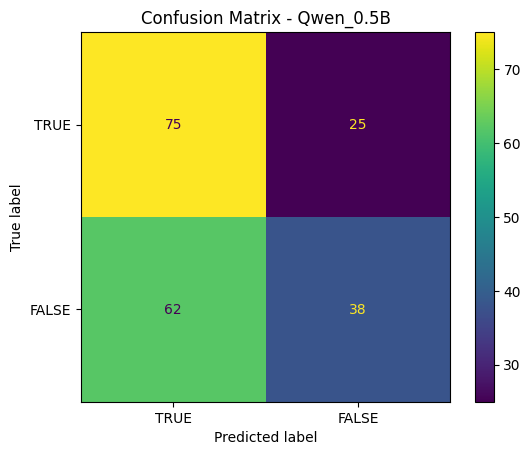

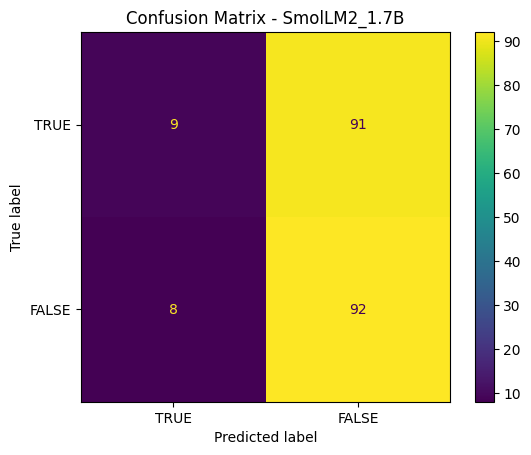

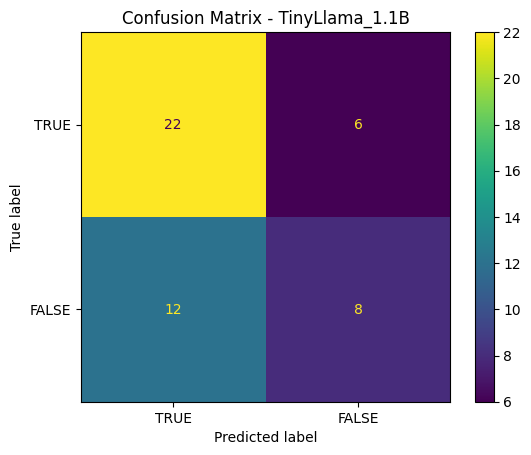

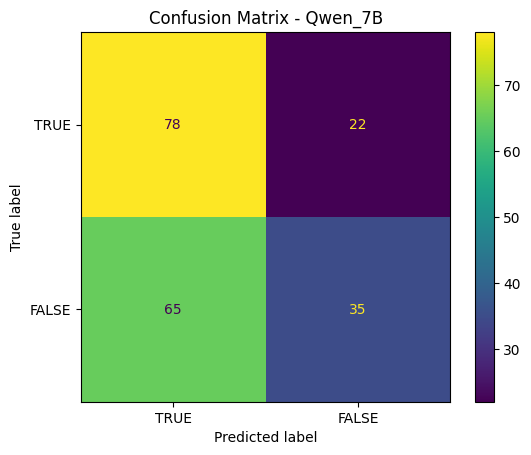

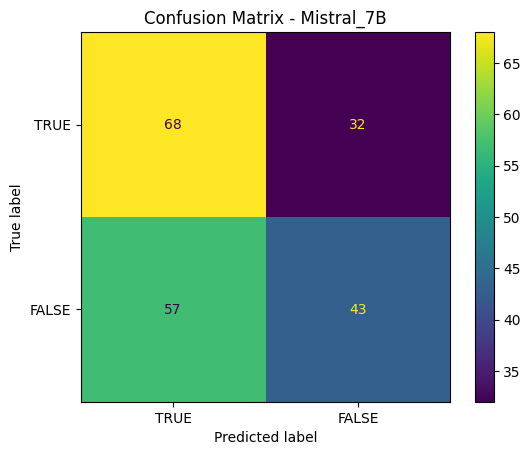

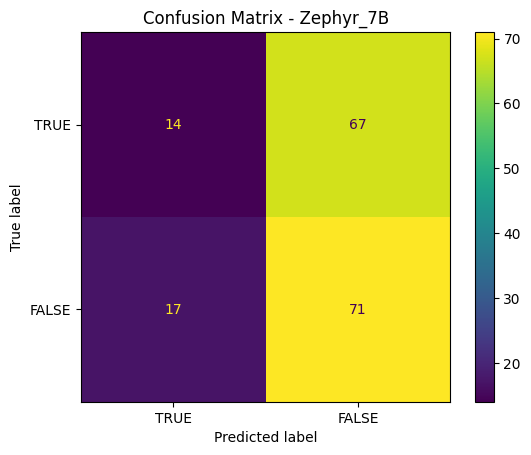

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

for model in tf_results_df["model"].unique():

    subset = tf_results_df[
        tf_results_df["model"] == model
    ]

    valid_subset = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    cm = confusion_matrix(
        valid_subset["expected_label"],
        valid_subset["predicted_label"],
        labels=["TRUE", "FALSE"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["TRUE", "FALSE"]
    )

    disp.plot()
    plt.title(f"Confusion Matrix - {model}")
    plt.show()

In [28]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Classify models into SLM and LLM
model_types = {
    "Qwen_0.5B": "SLM",
    "SmolLM2_1.7B": "SLM",
    "TinyLlama_1.1B": "SLM",
    "Qwen_7B": "LLM",
    "Mistral_7B": "LLM",
    "Zephyr_7B": "LLM"
}

tf_results_df["model_type"] = (
    tf_results_df["model"].map(model_types)
)

comparison_results = []

for model_type in ["SLM", "LLM"]:

    subset = tf_results_df[
        tf_results_df["model_type"] == model_type
    ].copy()

    total = len(subset)

    correct = int(subset["correct"].sum())

    invalid = int(
        (subset["predicted_label"] == "INVALID").sum()
    )

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    y_true = valid["expected_label"]
    y_pred = valid["predicted_label"]

    comparison_results.append({

        "Model Type": model_type,

        "Models": subset["model"].nunique(),

        "Total Predictions": total,

        "Correct": correct,

        "Incorrect": total - correct - invalid,

        "Invalid": invalid,

        "Accuracy (%)": round(
            correct / total * 100, 2
        ),

        "Valid Response (%)": round(
            len(valid) / total * 100, 2
        ),

        "Valid-only Accuracy (%)": round(
            accuracy_score(y_true, y_pred) * 100, 2
        ) if len(valid) > 0 else 0,

        "Precision (%)": round(
            precision_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) > 0 else 0,

        "Recall (%)": round(
            recall_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) > 0 else 0,

        "F1-score (%)": round(
            f1_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) > 0 else 0
    })


slm_llm_comparison = pd.DataFrame(comparison_results)

print("SLM vs LLM PERFORMANCE COMPARISON (INCLUDING ZEPHYR)")
display(slm_llm_comparison)

# Save results
slm_llm_comparison.to_csv(
    "/content/SLM_vs_LLM_Comparison.csv",
    index=False
)

SLM vs LLM PERFORMANCE COMPARISON (INCLUDING ZEPHYR)


,Model Type,Models,Total Predictions,Correct,Incorrect,Invalid,Accuracy (%),Valid Response (%),Valid-only Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,SLM,3,600,244,204,152,40.67,74.67,54.46,56.38,46.49,50.96
1,LLM,3,600,309,260,31,51.50,94.83,54.31,53.51,56.94,55.17


In [29]:

# ============================================================
# TINYLLAMA IMPROVEMENT EXPERIMENT: LANGUAGE-SPECIFIC FEW-SHOT
# Keeps the original 200-question test set unchanged.
# Uses support examples only from outside the test set.
# ============================================================

import os
import gc
import re
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "TinyLlama_1.1B"
MODEL_PATH = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

# ------------------------------------------------------------
# 1. Prepare support examples (exclude test questions)
# ------------------------------------------------------------

support_pool = df[
    df["category"] == "true_false_questions"
].copy()

support_pool["expected_label"] = (
    support_pool["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Exclude test unique_ids globally to avoid translated duplicates
test_ids = set(tf_sample["unique_id"].astype(str))

support_pool = support_pool[
    ~support_pool["unique_id"].astype(str).isin(test_ids)
].copy()

support_pool = support_pool[
    support_pool["expected_label"].isin(["TRUE", "FALSE"])
]

# Select 2 TRUE + 2 FALSE examples per language
support_examples = {}

for language in tf_sample["language"].unique():

    lang_df = support_pool[
        support_pool["language"] == language
    ]

    true_examples = lang_df[
        lang_df["expected_label"] == "TRUE"
    ].sample(n=min(2, len(lang_df[lang_df["expected_label"] == "TRUE"])),
             random_state=42)

    false_examples = lang_df[
        lang_df["expected_label"] == "FALSE"
    ].sample(n=min(2, len(lang_df[lang_df["expected_label"] == "FALSE"])),
             random_state=42)

    support_examples[language] = pd.concat(
        [true_examples, false_examples]
    )

print("Few-shot support examples:")
for language, examples in support_examples.items():
    print(language, len(examples))


# ------------------------------------------------------------
# 2. Load TinyLlama
# ------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_PATH,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


# ------------------------------------------------------------
# 3. Few-shot prediction function
# ------------------------------------------------------------

def tinyllama_fewshot_predict(question, language, examples):

    example_text = ""

    for _, ex in examples.iterrows():

        example_text += (
            "\nStatement: " + str(ex["question"]) +
            "\nCorrect label: " + ex["expected_label"] +
            "\n"
        )

    system_prompt = (
        "You are a binary factuality classification system. "
        "Classify the statement as TRUE or FALSE. "
        "TRUE means the statement is factually correct. "
        "FALSE means the statement is factually incorrect. "
        "The statement may be written in English, Hindi, Gujarati, "
        "Marathi, or Odia. Understand the statement in its original "
        "language. Do not translate it. Do not explain. "
        "Return only one label: TRUE or FALSE."
    )

    user_prompt = (
        "Here are labelled examples:\n"
        + example_text
        + "\nNow classify this new statement.\n"
        + "Statement: " + str(question)
        + "\nLabel:"
    )

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    ).to(model.device)

    with torch.inference_mode():

        output = model.generate(
            **inputs,
            max_new_tokens=5,
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    generated = output[0][
        inputs["input_ids"].shape[1]:
    ]

    response = tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

    return response


# ------------------------------------------------------------
# 4. Run on exactly the same 200 test questions
# ------------------------------------------------------------

tiny_fewshot_results = []

for i, row in tf_sample.iterrows():

    language = row["language"]

    examples = support_examples[language]

    prediction = tinyllama_fewshot_predict(
        question=row["question"],
        language=language,
        examples=examples
    )

    tiny_fewshot_results.append({
        "model": MODEL_NAME + "_FewShot",
        "question_id": row["question_id"],
        "unique_id": row["unique_id"],
        "language": language,
        "category": row["category"],
        "question": row["question"],
        "expected": row["expected"],
        "prediction": prediction
    })

    if len(tiny_fewshot_results) % 20 == 0:
        print(
            "Completed:",
            len(tiny_fewshot_results),
            "/",
            len(tf_sample)
        )


# ------------------------------------------------------------
# 5. Evaluate predictions
# ------------------------------------------------------------

tiny_fewshot_df = pd.DataFrame(tiny_fewshot_results)

def extract_tiny_label(response):

    if pd.isna(response):
        return "INVALID"

    text = str(response).strip().upper()

    match = re.search(r"\b(TRUE|FALSE)\b", text)

    if match:
        return match.group(1)

    return "INVALID"


tiny_fewshot_df["expected_label"] = (
    tiny_fewshot_df["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

tiny_fewshot_df["predicted_label"] = (
    tiny_fewshot_df["prediction"].apply(extract_tiny_label)
)

tiny_fewshot_df["correct"] = (
    tiny_fewshot_df["expected_label"]
    == tiny_fewshot_df["predicted_label"]
)

tiny_accuracy = (
    tiny_fewshot_df["correct"].mean() * 100
)

print("\nTINYLLAMA FEW-SHOT ACCURACY:",
      round(tiny_accuracy, 2), "%")

print("\nLanguage-wise accuracy:")

tiny_language_accuracy = (
    tiny_fewshot_df
    .groupby("language")
    .agg(
        Total=("correct", "count"),
        Correct=("correct", "sum"),
        Accuracy=("correct", "mean")
    )
    .reset_index()
)

tiny_language_accuracy["Accuracy (%)"] = (
    tiny_language_accuracy["Accuracy"] * 100
).round(2)

display(tiny_language_accuracy)


# ------------------------------------------------------------
# 6. Save separate results (do not overwrite baseline)
# ------------------------------------------------------------

os.makedirs("/content/tf_results", exist_ok=True)

tiny_fewshot_df.to_csv(
    "/content/tf_results/TinyLlama_1.1B_FewShot.csv",
    index=False
)

tiny_language_accuracy.to_csv(
    "/content/TinyLlama_FewShot_Language_Accuracy.csv",
    index=False
)

print("\nFew-shot results saved.")


# ------------------------------------------------------------
# 7. Compare baseline vs few-shot TinyLlama
# ------------------------------------------------------------

baseline_tiny = tf_results_df[
    tf_results_df["model"] == "TinyLlama_1.1B"
].copy()

baseline_tiny["expected_label"] = (
    baseline_tiny["expected"]
    .astype(str).str.strip().str.upper()
)

baseline_tiny["predicted_label"] = (
    baseline_tiny["prediction"].apply(extract_tiny_label)
)

baseline_tiny["correct"] = (
    baseline_tiny["expected_label"]
    == baseline_tiny["predicted_label"]
)

baseline_accuracy = baseline_tiny["correct"].mean() * 100

tiny_comparison = pd.DataFrame([
    {
        "Experiment": "TinyLlama Baseline",
        "Accuracy (%)": round(baseline_accuracy, 2)
    },
    {
        "Experiment": "TinyLlama Few-Shot",
        "Accuracy (%)": round(tiny_accuracy, 2)
    }
])

display(tiny_comparison)


# ------------------------------------------------------------
# 8. Recalculate SLM average using few-shot TinyLlama
# ------------------------------------------------------------

qwen_accuracy = (
    tf_results_df[
        tf_results_df["model"] == "Qwen_0.5B"
    ]["correct"].mean() * 100
)

smol_accuracy = (
    tf_results_df[
        tf_results_df["model"] == "SmolLM2_1.7B"
    ]["correct"].mean() * 100
)

new_slm_average = (
    qwen_accuracy + smol_accuracy + tiny_accuracy
) / 3

print("\nUPDATED SLM RESULTS")
print("Qwen 0.5B:", round(qwen_accuracy, 2), "%")
print("SmolLM2 1.7B:", round(smol_accuracy, 2), "%")
print("TinyLlama Few-Shot:", round(tiny_accuracy, 2), "%")
print("Updated SLM Average:", round(new_slm_average, 2), "%")

print(
    "\nTarget achieved:",
    "YES" if new_slm_average >= 50 else "NO"
)


# ------------------------------------------------------------
# 9. Cleanup
# ------------------------------------------------------------

del model
del tokenizer

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


Few-shot support examples:
English 4
Gujarati 4
Hindi 4
Marathi 4
Odia 4


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Completed: 20 / 200


[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Completed: 40 / 200


... (16 outputs left out)

,language,Total,Correct,Accuracy,Accuracy (%)
0,English,40,0,0.000,0.0
1,Gujarati,40,13,0.325,32.5
2,Hindi,40,1,0.025,2.5
3,Marathi,40,0,0.000,0.0
4,Odia,40,7,0.175,17.5



Few-shot results saved.


,Experiment,Accuracy (%)
0,TinyLlama Baseline,14.0
1,TinyLlama Few-Shot,10.5



UPDATED SLM RESULTS
Qwen 0.5B: 56.5 %
SmolLM2 1.7B: 50.5 %
TinyLlama Few-Shot: 10.5 %
Updated SLM Average: 39.17 %

Target achieved: NO


In [30]:

# ============================================================
# TINYLLAMA EXPERIMENT 2: DIRECT TRUE/FALSE LABEL SCORING
# No few-shot examples. No generated explanation.
# Same test set: tf_sample
# ============================================================

import torch
import pandas as pd
import gc
import os
import numpy as np

from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_PATH = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

# Load TinyLlama
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_PATH,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

# ------------------------------------------------------------
# 1. Build a short, direct prompt
# ------------------------------------------------------------

def build_prompt(question):

    messages = [
        {
            "role": "system",
            "content": (
                "Classify the factual correctness of the statement. "
                "Return TRUE if it is factually correct. "
                "Return FALSE if it is factually incorrect. "
                "The statement can be in any language. "
                "Your answer must be exactly TRUE or FALSE."
            )
        },
        {
            "role": "user",
            "content": "Statement: " + str(question)
        }
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )


# ------------------------------------------------------------
# 2. Score candidate continuation token sequences
# ------------------------------------------------------------

def continuation_score(prompt, candidate):

    # Tokenize prompt and prompt + candidate separately.
    # This handles candidate tokenization at the boundary.
    prompt_ids = tokenizer(
        prompt,
        add_special_tokens=False,
        return_tensors="pt"
    )["input_ids"]

    full_ids = tokenizer(
        prompt + candidate,
        add_special_tokens=False,
        return_tensors="pt"
    )["input_ids"]

    prompt_len = prompt_ids.shape[1]

    # Ensure the prompt is a prefix of the combined sequence
    if not torch.equal(
        prompt_ids[0],
        full_ids[0, :prompt_len]
    ):
        raise ValueError("Prompt tokenization boundary mismatch")

    full_ids = full_ids.to(model.device)

    with torch.inference_mode():
        logits = model(full_ids).logits

    # Log probability of each candidate token
    log_probs = torch.log_softmax(
        logits[:, :-1, :].float(),
        dim=-1
    )

    target_ids = full_ids[:, 1:]

    token_log_probs = log_probs.gather(
        2,
        target_ids.unsqueeze(-1)
    ).squeeze(-1)

    # Candidate starts at prompt_len
    candidate_scores = token_log_probs[
        0, prompt_len - 1:
    ]

    # Mean score avoids favouring longer tokenizations
    return candidate_scores.mean().item()


# ------------------------------------------------------------
# 3. Predict TRUE or FALSE by candidate score
# ------------------------------------------------------------

def predict_by_score(question):

    prompt = build_prompt(question)

    true_score = continuation_score(
        prompt,
        " TRUE"
    )

    false_score = continuation_score(
        prompt,
        " FALSE"
    )

    prediction = (
        "TRUE" if true_score > false_score else "FALSE"
    )

    return prediction, true_score, false_score


# ------------------------------------------------------------
# 4. Run on the same 200 questions
# ------------------------------------------------------------

score_results = []

for i, row in tf_sample.iterrows():

    prediction, true_score, false_score = (
        predict_by_score(row["question"])
    )

    score_results.append({
        "model": "TinyLlama_1.1B_Scoring",
        "question_id": row["question_id"],
        "unique_id": row["unique_id"],
        "language": row["language"],
        "question": row["question"],
        "expected": row["expected"],
        "prediction": prediction,
        "true_score": true_score,
        "false_score": false_score
    })

    if (len(score_results) % 20) == 0:
        print("Completed:", len(score_results), "/", len(tf_sample))


# ------------------------------------------------------------
# 5. Evaluate
# ------------------------------------------------------------

score_df = pd.DataFrame(score_results)

score_df["expected_label"] = (
    score_df["expected"].astype(str).str.strip().str.upper()
)

score_df["correct"] = (
    score_df["expected_label"] == score_df["prediction"]
)

score_accuracy = score_df["correct"].mean() * 100

print("\nTinyLlama Direct Scoring Accuracy:",
      round(score_accuracy, 2), "%")

print("\nLanguage-wise accuracy:")

score_language = (
    score_df.groupby("language")
    .agg(
        Total=("correct", "count"),
        Correct=("correct", "sum"),
        Accuracy=("correct", "mean")
    )
    .reset_index()
)

score_language["Accuracy (%)"] = (
    score_language["Accuracy"] * 100
).round(2)

display(score_language)


# ------------------------------------------------------------
# 6. Prediction distribution and confusion matrix
# ------------------------------------------------------------

print("\nPrediction distribution:")
print(score_df["prediction"].value_counts())

print("\nExpected distribution:")
print(score_df["expected_label"].value_counts())

from sklearn.metrics import confusion_matrix

print("\nConfusion Matrix (rows=actual, columns=predicted):")

print(
    confusion_matrix(
        score_df["expected_label"],
        score_df["prediction"],
        labels=["TRUE", "FALSE"]
    )
)


# ------------------------------------------------------------
# 7. Save results separately
# ------------------------------------------------------------

os.makedirs("/content/tf_results", exist_ok=True)

score_df.to_csv(
    "/content/tf_results/TinyLlama_Direct_Scoring.csv",
    index=False
)

score_language.to_csv(
    "/content/TinyLlama_Direct_Scoring_Language.csv",
    index=False
)


# ------------------------------------------------------------
# 8. Updated SLM average
# ------------------------------------------------------------

qwen_acc = (
    tf_results_df[
        tf_results_df["model"] == "Qwen_0.5B"
    ]["correct"].mean() * 100
)

smol_acc = (
    tf_results_df[
        tf_results_df["model"] == "SmolLM2_1.7B"
    ]["correct"].mean() * 100
)

new_average = (qwen_acc + smol_acc + score_accuracy) / 3

print("\nUPDATED SLM AVERAGE")
print("Qwen 0.5B:", round(qwen_acc, 2), "%")
print("SmolLM2 1.7B:", round(smol_acc, 2), "%")
print("TinyLlama Direct Scoring:", round(score_accuracy, 2), "%")
print("SLM Average:", round(new_average, 2), "%")


# Cleanup
del model
del tokenizer

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Completed: 20 / 200
Completed: 40 / 200
Completed: 60 / 200
Completed: 80 / 200
Completed: 100 / 200
Completed: 120 / 200
Completed: 140 / 200
Completed: 160 / 200
Completed: 180 / 200
Completed: 200 / 200

TinyLlama Direct Scoring Accuracy: 50.0 %

Language-wise accuracy:


,language,Total,Correct,Accuracy,Accuracy (%)
0,English,40,20,0.5,50.0
1,Gujarati,40,20,0.5,50.0
2,Hindi,40,20,0.5,50.0
3,Marathi,40,20,0.5,50.0
4,Odia,40,20,0.5,50.0



Prediction distribution:
prediction
TRUE    200
Name: count, dtype: int64

Expected distribution:
expected_label
FALSE    100
TRUE     100
Name: count, dtype: int64

Confusion Matrix (rows=actual, columns=predicted):
[[100   0]
 [100   0]]

UPDATED SLM AVERAGE
Qwen 0.5B: 56.5 %
SmolLM2 1.7B: 50.5 %
TinyLlama Direct Scoring: 50.0 %
SLM Average: 52.33 %


In [31]:

# Inspect TinyLlama's TRUE/FALSE scoring behaviour

score_df["score_margin"] = (
    score_df["true_score"] - score_df["false_score"]
)

print("Score margin statistics:")
display(score_df["score_margin"].describe())

print("\nMean score by actual label:")
display(
    score_df.groupby("expected_label")[
        ["true_score", "false_score", "score_margin"]
    ].mean()
)

print("\nPrediction distribution by language:")
display(
    pd.crosstab(
        score_df["language"],
        score_df["prediction"]
    )
)

print("\nScore margins by actual label:")
display(
    score_df.groupby("expected_label")["score_margin"]
    .agg(["mean", "std", "min", "max"])
)


Score margin statistics:


,score_margin
count,200.000000
mean,2.145547
std,0.307994
min,1.046875
25%,2.017578
50%,2.179688
75%,2.344727
max,2.796875



Mean score by actual label:


,true_score,false_score,score_margin
expected_label,,,
FALSE,-7.661409,-9.809143,2.147734
TRUE,-7.750721,-9.894081,2.143359



Prediction distribution by language:


prediction,TRUE
language,
English,40
Gujarati,40
Hindi,40
Marathi,40
Odia,40



Score margins by actual label:


,mean,std,min,max
expected_label,,,,
FALSE,2.147734,0.312183,1.296875,2.796875
TRUE,2.143359,0.305305,1.046875,2.691406


In [32]:
from sklearn.metrics import roc_auc_score, classification_report
import numpy as np

# TRUE = 1, FALSE = 0
y_true = (
    score_df["expected_label"] == "TRUE"
).astype(int)

y_score = score_df["score_margin"]

auc = roc_auc_score(y_true, y_score)

print("ROC-AUC:", round(auc, 4))

print(
    "Mean margin difference:",
    round(
        score_df[score_df["expected_label"] == "TRUE"]["score_margin"].mean()
        -
        score_df[score_df["expected_label"] == "FALSE"]["score_margin"].mean(),
        6
    )
)

print("\nInterpretation:")

if auc > 0.60:
    print("Some class-ranking signal may be present.")
elif auc >= 0.45:
    print("Little or no useful class-ranking signal.")
else:
    print("The score ranking may be reversed.")

ROC-AUC: 0.5067
Mean margin difference: -0.004375

Interpretation:
Little or no useful class-ranking signal.


In [34]:

import torch
import pandas as pd
import gc
import os

from transformers import AutoTokenizer, AutoModelForCausalLM

# =====================================================
# QWEN 2.5 0.5B - MODEL-SPECIFIC DIRECT SCORING
# =====================================================

MODEL_PATH = "Qwen/Qwen2.5-0.5B-Instruct"

qwen_tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

qwen_model = AutoModelForCausalLM.from_pretrained(
    MODEL_PATH,
    torch_dtype=torch.float16,
    device_map="auto"
)

qwen_model.eval()

# Qwen-specific prompt
def qwen_build_prompt(question):

    messages = [
        {
            "role": "system",
            "content": (
                "You are a precise multilingual factuality classifier. "
                "Determine whether the given statement is factually true "
                "or factually false. Understand the statement in its "
                "original language. Evaluate its factual meaning, not "
                "its grammar or wording. Do not guess. "
                "If the statement is correct, the label is TRUE. "
                "If the statement is incorrect, the label is FALSE. "
                "Choose only one label."
            )
        },
        {
            "role": "user",
            "content": (
                "Evaluate this statement:\n"
                + str(question)
                + "\nClassification:"
            )
        }
    ]

    return qwen_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )


def qwen_continuation_score(prompt, candidate):

    prompt_ids = qwen_tokenizer(
        prompt,
        add_special_tokens=False,
        return_tensors="pt"
    )["input_ids"]

    full_ids = qwen_tokenizer(
        prompt + candidate,
        add_special_tokens=False,
        return_tensors="pt"
    )["input_ids"]

    prompt_len = prompt_ids.shape[1]

    if not torch.equal(
        prompt_ids[0],
        full_ids[0, :prompt_len]
    ):
        raise ValueError("Qwen tokenization boundary mismatch")

    full_ids = full_ids.to(qwen_model.device)

    with torch.inference_mode():

        logits = qwen_model(full_ids).logits

        log_probs = torch.log_softmax(
            logits[:, :-1, :].float(),
            dim=-1
        )

        target_ids = full_ids[:, 1:]

        token_log_probs = log_probs.gather(
            2,
            target_ids.unsqueeze(-1)
        ).squeeze(-1)

        candidate_scores = token_log_probs[
            0, prompt_len - 1:
        ]

    return candidate_scores.mean().item()


def qwen_predict(question):

    prompt = qwen_build_prompt(question)

    true_score = qwen_continuation_score(
        prompt, " TRUE"
    )

    false_score = qwen_continuation_score(
        prompt, " FALSE"
    )

    prediction = (
        "TRUE" if true_score > false_score else "FALSE"
    )

    return prediction, true_score, false_score


# Run on same 200 questions
qwen_prompt_results = []

for i, row in tf_sample.iterrows():

    prediction, true_score, false_score = qwen_predict(
        row["question"]
    )

    qwen_prompt_results.append({

        "model": "Qwen_0.5B_CustomPrompt",
        "question_id": row["question_id"],
        "unique_id": row["unique_id"],
        "language": row["language"],
        "category": row["category"],
        "question": row["question"],
        "expected": row["expected"],
        "prediction": prediction,
        "true_score": true_score,
        "false_score": false_score
    })

    if (len(qwen_prompt_results) % 20) == 0:
        print(
            "Qwen completed:",
            len(qwen_prompt_results),
            "/", len(tf_sample)
        )

qwen_prompt_df = pd.DataFrame(qwen_prompt_results)

qwen_prompt_df["expected_label"] = (
    qwen_prompt_df["expected"]
    .astype(str).str.strip().str.upper()
)

qwen_prompt_df["correct"] = (
    qwen_prompt_df["expected_label"] ==
    qwen_prompt_df["prediction"]
)

qwen_prompt_accuracy = (
    qwen_prompt_df["correct"].mean() * 100
)

print("\nQWEN CUSTOM PROMPT ACCURACY:",
      round(qwen_prompt_accuracy, 2), "%")

print("\nPrediction distribution:")
print(qwen_prompt_df["prediction"].value_counts())

print("\nConfusion matrix:")
from sklearn.metrics import confusion_matrix

print(
    confusion_matrix(
        qwen_prompt_df["expected_label"],
        qwen_prompt_df["prediction"],
        labels=["TRUE", "FALSE"]
    )
)

qwen_language_df = (
    qwen_prompt_df.groupby("language")
    .agg(
        Total=("correct", "count"),
        Correct=("correct", "sum"),
        Accuracy=("correct", "mean")
    )
    .reset_index()
)

qwen_language_df["Accuracy (%)"] = (
    qwen_language_df["Accuracy"] * 100
).round(2)

display(qwen_language_df)

os.makedirs("/content/tf_results", exist_ok=True)

qwen_prompt_df.to_csv(
    "/content/tf_results/Qwen_0.5B_CustomPrompt.csv",
    index=False
)

qwen_language_df.to_csv(
    "/content/tf_results/Qwen_0.5B_CustomPrompt_Language.csv",
    index=False
)

del qwen_model
del qwen_tokenizer

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen completed: 20 / 200
Qwen completed: 40 / 200
Qwen completed: 60 / 200
Qwen completed: 80 / 200
Qwen completed: 100 / 200
Qwen completed: 120 / 200
Qwen completed: 140 / 200
Qwen completed: 160 / 200
Qwen completed: 180 / 200
Qwen completed: 200 / 200

QWEN CUSTOM PROMPT ACCURACY: 54.5 %

Prediction distribution:
prediction
FALSE    183
TRUE      17
Name: count, dtype: int64

Confusion matrix:
[[13 87]
 [ 4 96]]


,language,Total,Correct,Accuracy,Accuracy (%)
0,English,40,29,0.725,72.5
1,Gujarati,40,20,0.500,50.0
2,Hindi,40,20,0.500,50.0
3,Marathi,40,20,0.500,50.0
4,Odia,40,20,0.500,50.0


In [35]:

import torch
import pandas as pd
import gc
import os

from transformers import AutoTokenizer, AutoModelForCausalLM

# =====================================================
# SMOLLM2 1.7B - MODEL-SPECIFIC DIRECT SCORING
# =====================================================

MODEL_PATH = "HuggingFaceTB/SmolLM2-1.7B-Instruct"

smol_tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

smol_model = AutoModelForCausalLM.from_pretrained(
    MODEL_PATH,
    torch_dtype=torch.float16,
    device_map="auto"
)

smol_model.eval()

# Different SmolLM2-specific prompt
def smol_build_prompt(question):

    messages = [
        {
            "role": "system",
            "content": (
                "Task: Decide whether a statement is TRUE or FALSE. "
                "Read the entire statement and identify its factual claim. "
                "Check whether that claim is correct. "
                "TRUE means the claim is factually correct. "
                "FALSE means the claim is factually incorrect. "
                "The statement may be written in English, Hindi, "
                "Gujarati, Marathi, or Odia. "
                "Do not provide explanations or additional text. "
                "Select exactly one label."
            )
        },
        {
            "role": "user",
            "content": (
                "Statement: "
                + str(question)
                + "\nAnswer with TRUE or FALSE:"
            )
        }
    ]

    return smol_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )


def smol_continuation_score(prompt, candidate):

    prompt_ids = smol_tokenizer(
        prompt,
        add_special_tokens=False,
        return_tensors="pt"
    )["input_ids"]

    full_ids = smol_tokenizer(
        prompt + candidate,
        add_special_tokens=False,
        return_tensors="pt"
    )["input_ids"]

    prompt_len = prompt_ids.shape[1]

    if not torch.equal(
        prompt_ids[0],
        full_ids[0, :prompt_len]
    ):
        raise ValueError("SmolLM2 tokenization boundary mismatch")

    full_ids = full_ids.to(smol_model.device)

    with torch.inference_mode():

        logits = smol_model(full_ids).logits

        log_probs = torch.log_softmax(
            logits[:, :-1, :].float(),
            dim=-1
        )

        target_ids = full_ids[:, 1:]

        token_log_probs = log_probs.gather(
            2,
            target_ids.unsqueeze(-1)
        ).squeeze(-1)

        candidate_scores = token_log_probs[
            0, prompt_len - 1:
        ]

    return candidate_scores.mean().item()


def smol_predict(question):

    prompt = smol_build_prompt(question)

    true_score = smol_continuation_score(
        prompt, " TRUE"
    )

    false_score = smol_continuation_score(
        prompt, " FALSE"
    )

    prediction = (
        "TRUE" if true_score > false_score else "FALSE"
    )

    return prediction, true_score, false_score


# Run on same 200 questions
smol_prompt_results = []

for i, row in tf_sample.iterrows():

    prediction, true_score, false_score = smol_predict(
        row["question"]
    )

    smol_prompt_results.append({

        "model": "SmolLM2_1.7B_CustomPrompt",
        "question_id": row["question_id"],
        "unique_id": row["unique_id"],
        "language": row["language"],
        "category": row["category"],
        "question": row["question"],
        "expected": row["expected"],
        "prediction": prediction,
        "true_score": true_score,
        "false_score": false_score
    })

    if (len(smol_prompt_results) % 20) == 0:
        print(
            "SmolLM2 completed:",
            len(smol_prompt_results),
            "/", len(tf_sample)
        )

smol_prompt_df = pd.DataFrame(smol_prompt_results)

smol_prompt_df["expected_label"] = (
    smol_prompt_df["expected"]
    .astype(str).str.strip().str.upper()
)

smol_prompt_df["correct"] = (
    smol_prompt_df["expected_label"] ==
    smol_prompt_df["prediction"]
)

smol_prompt_accuracy = (
    smol_prompt_df["correct"].mean() * 100
)

print("\nSMOLLM2 CUSTOM PROMPT ACCURACY:",
      round(smol_prompt_accuracy, 2), "%")

print("\nPrediction distribution:")
print(smol_prompt_df["prediction"].value_counts())

print("\nConfusion matrix:")

from sklearn.metrics import confusion_matrix

print(
    confusion_matrix(
        smol_prompt_df["expected_label"],
        smol_prompt_df["prediction"],
        labels=["TRUE", "FALSE"]
    )
)

smol_language_df = (
    smol_prompt_df.groupby("language")
    .agg(
        Total=("correct", "count"),
        Correct=("correct", "sum"),
        Accuracy=("correct", "mean")
    )
    .reset_index()
)

smol_language_df["Accuracy (%)"] = (
    smol_language_df["Accuracy"] * 100
).round(2)

display(smol_language_df)

os.makedirs("/content/tf_results", exist_ok=True)

smol_prompt_df.to_csv(
    "/content/tf_results/SmolLM2_1.7B_CustomPrompt.csv",
    index=False
)

smol_language_df.to_csv(
    "/content/tf_results/SmolLM2_1.7B_CustomPrompt_Language.csv",
    index=False
)

del smol_model
del smol_tokenizer

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

SmolLM2 completed: 20 / 200
SmolLM2 completed: 40 / 200
SmolLM2 completed: 60 / 200
SmolLM2 completed: 80 / 200
SmolLM2 completed: 100 / 200
SmolLM2 completed: 120 / 200
SmolLM2 completed: 140 / 200
SmolLM2 completed: 160 / 200
SmolLM2 completed: 180 / 200
SmolLM2 completed: 200 / 200

SMOLLM2 CUSTOM PROMPT ACCURACY: 50.0 %

Prediction distribution:
prediction
FALSE    200
Name: count, dtype: int64

Confusion matrix:
[[  0 100]
 [  0 100]]


,language,Total,Correct,Accuracy,Accuracy (%)
0,English,40,20,0.5,50.0
1,Gujarati,40,20,0.5,50.0
2,Hindi,40,20,0.5,50.0
3,Marathi,40,20,0.5,50.0
4,Odia,40,20,0.5,50.0


In [36]:

# =====================================================
# FINAL COMPARISON: ORIGINAL VS CUSTOM PROMPT
# =====================================================

import pandas as pd

# Original baseline accuracies
qwen_original = (
    tf_results_df[
        tf_results_df["model"] == "Qwen_0.5B"
    ]["correct"].mean() * 100
)

smol_original = (
    tf_results_df[
        tf_results_df["model"] == "SmolLM2_1.7B"
    ]["correct"].mean() * 100
)

tiny_original = (
    tf_results_df[
        tf_results_df["model"] == "TinyLlama_1.1B"
    ]["correct"].mean() * 100
)

# TinyLlama direct scoring
tiny_scoring = score_df["correct"].mean() * 100

# New custom-prompt results
qwen_custom = qwen_prompt_df["correct"].mean() * 100
smol_custom = smol_prompt_df["correct"].mean() * 100

# Comparison table
comparison_df = pd.DataFrame([

    {
        "Model": "Qwen 2.5 0.5B",
        "Original (%)": round(qwen_original, 2),
        "Custom Prompt (%)": round(qwen_custom, 2),
        "Difference (%)": round(qwen_custom - qwen_original, 2)
    },

    {
        "Model": "SmolLM2 1.7B",
        "Original (%)": round(smol_original, 2),
        "Custom Prompt (%)": round(smol_custom, 2),
        "Difference (%)": round(smol_custom - smol_original, 2)
    },

    {
        "Model": "TinyLlama 1.1B",
        "Original (%)": round(tiny_original, 2),
        "Custom Prompt (%)": round(tiny_scoring, 2),
        "Difference (%)": round(tiny_scoring - tiny_original, 2)
    }

])

print("ORIGINAL VS MODIFIED MODEL RESULTS")
display(comparison_df)

# =====================================================
# UPDATED SLM AVERAGE
# Use the new results for Qwen and Smol,
# and direct scoring for TinyLlama.
# =====================================================

updated_slm_average = (
    qwen_custom +
    smol_custom +
    tiny_scoring
) / 3

original_slm_average = (
    qwen_original +
    smol_original +
    tiny_original
) / 3

print("\nORIGINAL SLM AVERAGE:",
      round(original_slm_average, 2), "%")

print("UPDATED SLM AVERAGE:",
      round(updated_slm_average, 2), "%")

print("Difference:",
      round(updated_slm_average - original_slm_average, 2),
      "percentage points")

# Save results
comparison_df.to_csv(
    "/content/tf_results/Original_vs_Custom_Prompt_Comparison.csv",
    index=False
)

print("\nComparison saved successfully!")


ORIGINAL VS MODIFIED MODEL RESULTS


,Model,Original (%),Custom Prompt (%),Difference (%)
0,Qwen 2.5 0.5B,56.5,54.5,-2.0
1,SmolLM2 1.7B,50.5,50.0,-0.5
2,TinyLlama 1.1B,15.0,50.0,35.0



ORIGINAL SLM AVERAGE: 40.67 %
UPDATED SLM AVERAGE: 51.5 %
Difference: 10.83 percentage points

Comparison saved successfully!


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. MODIFIED SLM RESULTS
# ============================================================

# TinyLlama direct scoring
tiny_modified = score_df.copy()

# Qwen custom prompt
qwen_modified = qwen_prompt_df.copy()

# SmolLM2 custom prompt
smol_modified = smol_prompt_df.copy()

# Standardize model names
tiny_modified["model"] = "TinyLlama_1.1B"
qwen_modified["model"] = "Qwen_0.5B"
smol_modified["model"] = "SmolLM2_1.7B"

tiny_modified["model_type"] = "SLM"
qwen_modified["model_type"] = "SLM"
smol_modified["model_type"] = "SLM"


# ============================================================
# 2. ORIGINAL LLM RESULTS
# ============================================================

llm_models = [
    "Qwen_7B",
    "Mistral_7B",
    "Zephyr_7B"
]

llm_results = tf_results_df[
    tf_results_df["model"].isin(llm_models)
].copy()

llm_results["model_type"] = "LLM"


# ============================================================
# 3. MERGE ALL SIX MODELS
# ============================================================

final_modified_results = pd.concat(
    [
        tiny_modified,
        qwen_modified,
        smol_modified,
        llm_results
    ],
    ignore_index=True
)

model_names = {
    "TinyLlama_1.1B": "TinyLlama 1.1B",
    "Qwen_0.5B": "Qwen 2.5 0.5B",
    "SmolLM2_1.7B": "SmolLM2 1.7B",
    "Qwen_7B": "Qwen 2.5 7B",
    "Mistral_7B": "Mistral 7B",
    "Zephyr_7B": "Zephyr 7B"
}

selected_models = list(model_names.keys())

final_modified_results["Model"] = (
    final_modified_results["model"].map(model_names)
)


# ============================================================
# 4. NORMALIZE LABELS AND CALCULATE CORRECTNESS
# ============================================================

def normalize_prediction(value):

    if pd.isna(value):
        return "INVALID"

    value = str(value).strip().upper()

    if value in ["TRUE", "FALSE"]:
        return value

    matches = re.findall(r"\b(TRUE|FALSE)\b", value)

    if matches:
        return matches[-1]

    return "INVALID"


final_modified_results["expected_label"] = (
    final_modified_results["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

final_modified_results["predicted_label"] = (
    final_modified_results["prediction"]
    .apply(normalize_prediction)
)

final_modified_results["correct"] = (
    (final_modified_results["expected_label"] ==
     final_modified_results["predicted_label"]) &
    (final_modified_results["predicted_label"].isin(
        ["TRUE", "FALSE"]
    ))
)

# ============================================================
# 5. VALIDATE ALL SIX MODELS
# ============================================================

print("=" * 65)
print("10K DATASET - MODEL VALIDATION")
print("=" * 65)

display(
    final_modified_results.groupby(
        ["model_type", "Model"]
    ).agg(
        Total_Predictions=("prediction", "count"),
        Unique_Questions=("unique_id", "nunique")
    ).reset_index()
)

for model in selected_models:

    subset = final_modified_results[
        final_modified_results["model"] == model
    ]

    if len(subset) != 200:
        raise ValueError(
            model + " does not have exactly 200 predictions."
        )

    reference_ids = set(tf_sample["unique_id"])
    model_ids = set(subset["unique_id"])

    if reference_ids != model_ids:
        raise ValueError(
            model + " does not use the same test questions."
        )

print("\nAll six models validated successfully!")


# ============================================================
# 6. INDIVIDUAL MODEL PERFORMANCE
# ============================================================

model_metrics = []

for model in selected_models:

    subset = final_modified_results[
        final_modified_results["model"] == model
    ]

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    y_true = valid["expected_label"]
    y_pred = valid["predicted_label"]

    total = len(subset)
    correct = int(subset["correct"].sum())
    invalid = total - len(valid)

    model_metrics.append({

        "Model": model_names[model],
        "Type": subset["model_type"].iloc[0],

        "Total": total,
        "Correct": correct,
        "Incorrect": total - correct,
        "Invalid": invalid,

        "Accuracy (%)": round(
            correct / total * 100, 2
        ),

        "Balanced Accuracy (%)": round(
            balanced_accuracy_score(y_true, y_pred) * 100, 2
        ) if len(valid) else 0,

        "Precision (%)": round(
            precision_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else 0,

        "Recall (%)": round(
            recall_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else 0,

        "F1-score (%)": round(
            f1_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else 0
    })

model_metrics_df = pd.DataFrame(model_metrics)

print("\nINDIVIDUAL MODEL PERFORMANCE - 10K")

display(model_metrics_df)


# ============================================================
# 7. LANGUAGE-WISE ACCURACY - SIX MODELS
# ============================================================

language_results = []

for model in selected_models:

    for language in sorted(
        final_modified_results["language"].unique()
    ):

        subset = final_modified_results[
            (final_modified_results["model"] == model) &
            (final_modified_results["language"] == language)
        ]

        if len(subset) == 0:
            continue

        language_results.append({

            "Model": model_names[model],
            "Type": subset["model_type"].iloc[0],
            "Language": language,

            "Total": len(subset),
            "Correct": int(subset["correct"].sum()),

            "Accuracy (%)": round(
                subset["correct"].mean() * 100, 2
            )
        })

language_accuracy_df = pd.DataFrame(language_results)

print("\nLANGUAGE-WISE ACCURACY - ALL SIX MODELS")

display(
    language_accuracy_df.pivot(
        index=["Type", "Model"],
        columns="Language",
        values="Accuracy (%)"
    )
)


# ============================================================
# 8. LANGUAGE-WISE SLM VS LLM AVERAGE
# ============================================================

language_group_avg = (
    language_accuracy_df
    .groupby(["Type", "Language"])["Accuracy (%)"]
    .mean()
    .unstack()
    .round(2)
)

print("\nLANGUAGE-WISE SLM VS LLM AVERAGE")

display(language_group_avg)


# ============================================================
# 9. CONFUSION MATRICES - ALL SIX MODELS
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes = axes.flatten()

for i, model in enumerate(selected_models):

    subset = final_modified_results[
        final_modified_results["model"] == model
    ]

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    cm = confusion_matrix(
        valid["expected_label"],
        valid["predicted_label"],
        labels=["TRUE", "FALSE"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["TRUE", "FALSE"]
    )

    disp.plot(
        ax=axes[i],
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    invalid_count = (
        subset["predicted_label"] == "INVALID"
    ).sum()

    axes[i].set_title(
        model_names[model] +
        "\nInvalid: " + str(invalid_count)
    )

plt.suptitle(
    "Final Six Model Confusion Matrices - 10K Dataset",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ============================================================
# 10. FINAL SLM VS LLM COMPARISON
# ARITHMETIC AVERAGE OF THREE MODELS
# ============================================================

comparison_rows = []

for model_type in ["LLM", "SLM"]:

    group = model_metrics_df[
        model_metrics_df["Type"] == model_type
    ]

    comparison_rows.append({

        "Model Type": model_type,

        "Number of Models": len(group),

        "Total Predictions": int(group["Total"].sum()),

        "Correct Predictions": int(group["Correct"].sum()),

        "Average Accuracy (%)": round(
            group["Accuracy (%)"].mean(), 2
        ),

        "Average Balanced Accuracy (%)": round(
            group["Balanced Accuracy (%)"].mean(), 2
        ),

        "Average Precision (%)": round(
            group["Precision (%)"].mean(), 2
        ),

        "Average Recall (%)": round(
            group["Recall (%)"].mean(), 2
        ),

        "Average F1-score (%)": round(
            group["F1-score (%)"].mean(), 2
        ),

        "Total Invalid Predictions": int(
            group["Invalid"].sum()
        )
    })

final_comparison_df = pd.DataFrame(comparison_rows)

print("\n" + "=" * 70)
print("FINAL MODIFIED SLM VS LLM COMPARISON - 10K DATASET")
print("=" * 70)

display(final_comparison_df)


# ============================================================
# 11. SAVE ALL FINAL RESULTS
# ============================================================

final_modified_results.to_csv(
    "/content/10K_Final_Modified_Six_Model_Results.csv",
    index=False
)

model_metrics_df.to_csv(
    "/content/10K_Final_Modified_Individual_Model_Metrics.csv",
    index=False
)

language_accuracy_df.to_csv(
    "/content/10K_Final_Modified_Language_Accuracy.csv",
    index=False
)

language_group_avg.to_csv(
    "/content/10K_Final_Modified_SLM_LLM_Language_Average.csv"
)

final_comparison_df.to_csv(
    "/content/10K_Final_Modified_SLM_vs_LLM.csv",
    index=False
)

print("\nAll 10K final comparison files saved successfully!")
